# Retail Sales Analysis: Where Does the Business Make and Lose Money? (SQL)

**Business question:** A retailer has high sales, but high sales don't mean high profit. Which products, discounts and regions are draining profit, and what should the business change?



## Step 0. Set up (run this first)
In Google Colab, this cell opens a file picker. Choose **superstore_sales.csv** from the project folder.
It also creates an `images` folder for the charts.

In [83]:
import os
os.makedirs("images", exist_ok=True)

# Upload the data file if it isn't here yet (Colab starts empty every session)
if not os.path.exists("superstore_sales.csv"):
    from google.colab import files
    files.upload()

print("Data file found:", os.path.exists("superstore_sales.csv"))

Data file found: True


## Step 1. Load the CSV into a SQL database
We use **SQLite**, a small SQL database built into Python. The CSV becomes a table called `sales`.

In [84]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/superstore_sales.csv")
conn = sqlite3.connect("sales.db")
df.to_sql("sales", conn, if_exists="replace", index=False)

print("Rows loaded:", len(df))

Rows loaded: 8399


## Step 2. A helper so each query is one line
`sql("SELECT ...")` runs the query and shows the result as a table.

In [85]:
def sql(query):
    return pd.read_sql(query, conn)

## Step 3. Look at the data
Always look before you analyse.

In [86]:
sql("SELECT * FROM sales LIMIT 10")

,row_id,order_id,order_date,order_priority,order_quantity,sales,discount,ship_mode,profit,unit_price,...,customer_name,province,region,customer_segment,product_category,product_sub_category,product_name,product_container,product_base_margin,ship_date
0,1,3,2010-10-13,Low,6,261.5400,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,2010-10-20
1,49,293,2012-10-01,High,49,10123.0200,0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,2012-10-02
2,50,293,2012-10-01,High,27,244.5700,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D¨ Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,2012-10-03
3,80,483,2011-07-10,High,30,4965.7595,0.08,Regular Air,1198.97,195.99,...,Clay Rozendal,Nunavut,Nunavut,Corporate,Technology,Telephones and Communication,R380,Small Box,0.58,2011-07-12
4,85,515,2010-08-28,Not Specified,19,394.2700,0.08,Regular Air,30.94,21.78,...,Carlos Soltero,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,Holmes HEPA Air Purifier,Medium Box,0.50,2010-08-30
5,86,515,2010-08-28,Not Specified,21,146.6900,0.05,Regular Air,4.43,6.64,...,Carlos Soltero,Nunavut,Nunavut,Consumer,Furniture,Office Furnishings,G.E. Longer-Life Indoor Recessed Floodlight Bulbs,Small Pack,0.37,2010-08-30
6,97,613,2011-06-17,High,12,93.5400,0.03,Regular Air,-54.04,7.30,...,Carl Jackson,Nunavut,Nunavut,Corporate,Office Supplies,Binders and Binder Accessories,"Angle-D Binders with Locking Rings, Label Holders",Small Box,0.38,2011-06-17
7,98,613,2011-06-17,High,22,905.0800,0.09,Regular Air,127.70,42.76,...,Carl Jackson,Nunavut,Nunavut,Corporate,Office Supplies,Storage & Organization,"SAFCO Mobile Desk Side File, Wire Frame",Small Box,NaN,2011-06-18
8,103,643,2011-03-24,High,21,2781.8200,0.07,Express Air,-695.26,138.14,...,Monica Federle,Nunavut,Nunavut,Corporate,Office Supplies,Storage & Organization,"SAFCO Commercial Wire Shelving, Black",Large Box,NaN,2011-03-25
9,107,678,2010-02-26,Low,44,228.4100,0.07,Regular Air,-226.36,4.98,...,Dorothy Badders,Nunavut,Nunavut,Home Office,Office Supplies,Paper,Xerox 198,Small Box,0.38,2010-02-26


In [87]:
sql("""
SELECT COUNT(*)        AS total_rows,
       MIN(order_date) AS first_order,
       MAX(order_date) AS last_order
FROM sales
""")

,total_rows,first_order,last_order
0,8399,2009-01-01,2012-12-30


## Step 4. Clean the data
Check the region names. One of them is misspelled.

In [88]:
sql("""
SELECT region, COUNT(*) AS rows_count
FROM sales
GROUP BY region
ORDER BY region
""")

,region,rows_count
0,Atlantic,1080
1,Northwest Territories,394
2,Nunavut,79
3,Ontario,1826
4,Prarie,1706
5,Quebec,781
6,West,1991
7,Yukon,542


`UPDATE` changes data instead of returning a table, so it runs differently: `conn.execute(...)` then `conn.commit()` to save it.

In [89]:
conn.execute("UPDATE sales SET region = 'Prairie' WHERE region = 'Prarie'")
conn.commit()

# Check the fix worked
sql("SELECT region, COUNT(*) AS rows_count FROM sales GROUP BY region ORDER BY region")

,region,rows_count
0,Atlantic,1080
1,Northwest Territories,394
2,Nunavut,79
3,Ontario,1826
4,Prairie,1706
5,Quebec,781
6,West,1991
7,Yukon,542


Check for missing values in the money columns.

In [90]:
sql("""
SELECT SUM(CASE WHEN sales  IS NULL THEN 1 ELSE 0 END) AS missing_sales,
       SUM(CASE WHEN profit IS NULL THEN 1 ELSE 0 END) AS missing_profit
FROM sales
""")

,missing_sales,missing_profit
0,0,0


## Step 5. Headline numbers
How big is this business?

In [91]:
sql("""
SELECT ROUND(SUM(sales), 0)                       AS total_sales,
       ROUND(SUM(profit), 0)                      AS total_profit,
       ROUND(SUM(profit) * 100.0 / SUM(sales), 1) AS profit_margin_pct,
       COUNT(DISTINCT order_id)                   AS total_orders,
       COUNT(DISTINCT customer_name)              AS total_customers
FROM sales
""")

,total_sales,total_profit,profit_margin_pct,total_orders,total_customers
0,14915601.0,1521768.0,10.2,5496,795


## Step 6. Sales and profit by year
Is the business growing? `SUBSTR(order_date, 1, 4)` takes the first 4 characters of the date, which is the year.

In [92]:
sql("""
SELECT SUBSTR(order_date, 1, 4) AS order_year,
       ROUND(SUM(sales), 0)     AS total_sales,
       ROUND(SUM(profit), 0)    AS total_profit,
       ROUND(SUM(profit) * 100.0 / SUM(sales), 1) AS profit_margin_pct
FROM sales
GROUP BY order_year
ORDER BY order_year
""")

,order_year,total_sales,total_profit,profit_margin_pct
0,2009,4209139.0,434539.0,10.3
1,2010,3549681.0,363871.0,10.3
2,2011,3436817.0,381456.0,11.1
3,2012,3719964.0,341902.0,9.2


## Step 7. Which product categories make the money?

In [93]:
sql("""
SELECT product_category,
       ROUND(SUM(sales), 0)                       AS total_sales,
       ROUND(SUM(profit), 0)                      AS total_profit,
       ROUND(SUM(profit) * 100.0 / SUM(sales), 1) AS profit_margin_pct
FROM sales
GROUP BY product_category
ORDER BY total_profit DESC
""")

,product_category,total_sales,total_profit,profit_margin_pct
0,Technology,5984248.0,886314.0,14.8
1,Office Supplies,3752762.0,518021.0,13.8
2,Furniture,5178591.0,117433.0,2.3


## Step 8. Which sub-categories LOSE money?
This is usually the most useful finding.
`HAVING` filters **after** grouping. `WHERE` filters **before** grouping.

In [94]:
sql("""
SELECT product_sub_category,
       ROUND(SUM(sales), 0)  AS total_sales,
       ROUND(SUM(profit), 0) AS total_profit
FROM sales
GROUP BY product_sub_category
HAVING SUM(profit) < 0
ORDER BY total_profit
""")

,product_sub_category,total_sales,total_profit
0,Tables,1896008.0,-99063.0
1,Bookcases,822652.0,-33582.0
2,"Scissors, Rulers and Trimmers",80996.0,-7799.0
3,Rubber Bands,15007.0,-103.0


A chart makes this finding obvious to a manager. Red bars lose money.

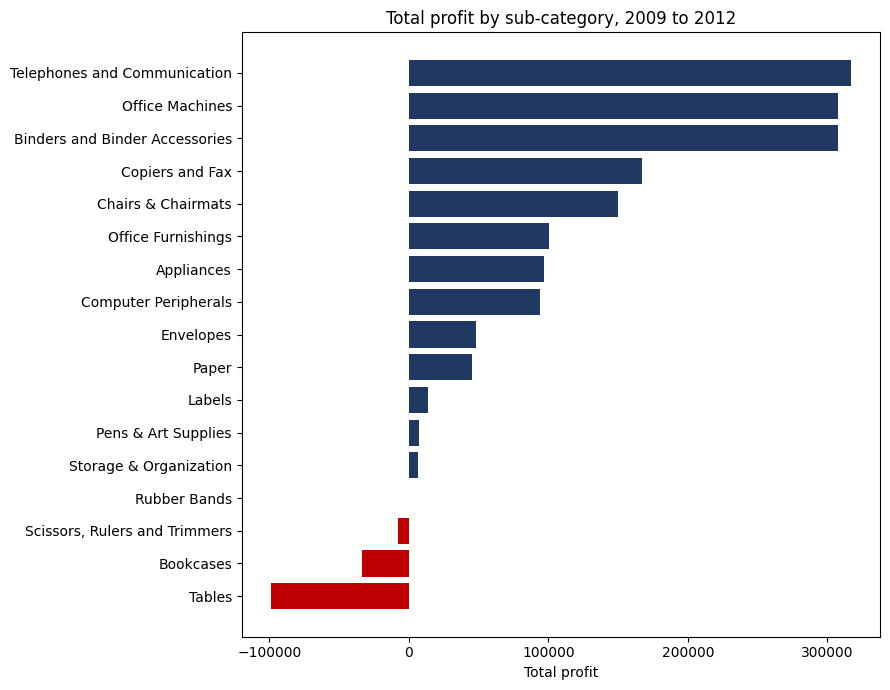

In [95]:
profit_by_sub = sql("""
SELECT product_sub_category, SUM(profit) AS total_profit
FROM sales
GROUP BY product_sub_category
ORDER BY total_profit
""")

colours = ["#C00000" if p < 0 else "#1F3864" for p in profit_by_sub["total_profit"]]
plt.figure(figsize=(9, 7))
plt.barh(profit_by_sub["product_sub_category"], profit_by_sub["total_profit"], color=colours)
plt.title("Total profit by sub-category, 2009 to 2012")
plt.xlabel("Total profit")
plt.tight_layout()
plt.savefig("images/profit_by_sub_category.png", dpi=120)
plt.show()

## Step 9. Do bigger discounts go with lower profit?
`CASE` puts each row into a discount band.

In [96]:
discounts = sql("""
SELECT CASE
           WHEN discount = 0     THEN '1. No discount'
           WHEN discount <= 0.05 THEN '2. Up to 5%'
           WHEN discount <= 0.08 THEN '3. 6% to 8%'
           ELSE                       '4. Over 8%'
       END                                        AS discount_band,
       COUNT(*)                                   AS order_lines,
       ROUND(SUM(sales), 0)                       AS total_sales,
       ROUND(SUM(profit) * 100.0 / SUM(sales), 1) AS profit_margin_pct
FROM sales
GROUP BY discount_band
ORDER BY discount_band
""")
discounts

,discount_band,order_lines,total_sales,profit_margin_pct
0,1. No discount,756,1493748.0,12.6
1,2. Up to 5%,3906,6932777.0,11.9
2,3. 6% to 8%,2209,3983045.0,8.0
3,4. Over 8%,1528,2506031.0,7.5


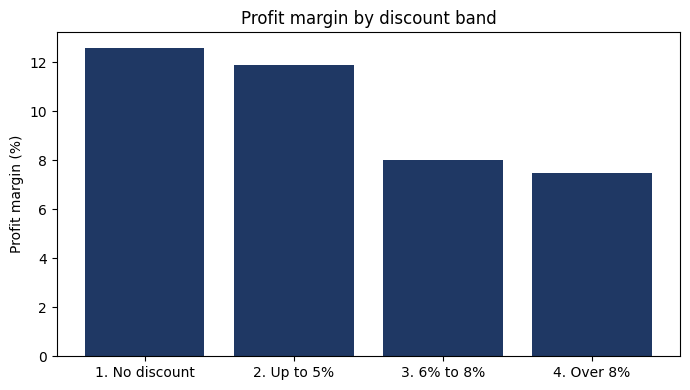

In [97]:
plt.figure(figsize=(7, 4))
plt.bar(discounts["discount_band"], discounts["profit_margin_pct"], color="#1F3864")
plt.title("Profit margin by discount band")
plt.ylabel("Profit margin (%)")
plt.tight_layout()
plt.savefig("images/margin_by_discount.png", dpi=120)
plt.show()

## Step 10. Region performance

In [98]:
sql("""
SELECT region,
       ROUND(SUM(sales), 0)                       AS total_sales,
       ROUND(SUM(profit), 0)                      AS total_profit,
       ROUND(SUM(profit) * 100.0 / SUM(sales), 1) AS profit_margin_pct
FROM sales
GROUP BY region
ORDER BY total_profit DESC
""")

,region,total_sales,total_profit,profit_margin_pct
0,Ontario,3063212.0,346869.0,11.3
1,Prairie,2837305.0,321160.0,11.3
2,West,3597549.0,297009.0,8.3
3,Atlantic,2014248.0,238961.0,11.9
4,Quebec,1510195.0,140427.0,9.3
5,Northwest Territories,800847.0,100653.0,12.6
6,Yukon,975867.0,73849.0,7.6
7,Nunavut,116376.0,2841.0,2.4


## Step 11. Top 10 customers and their share of total sales
The **subquery** `(SELECT SUM(sales) FROM sales)` gives the grand total, so we can work out a percentage.

In [99]:
sql("""
SELECT customer_name,
       customer_segment,
       ROUND(SUM(sales), 0)                                          AS customer_sales,
       ROUND(SUM(sales) * 100.0 / (SELECT SUM(sales) FROM sales), 2) AS share_of_total_pct
FROM sales
GROUP BY customer_name, customer_segment
ORDER BY customer_sales DESC
LIMIT 10
""")

,customer_name,customer_segment,customer_sales,share_of_total_pct
0,Emily Phan,Consumer,117124.0,0.79
1,Roy Skaria,Corporate,92542.0,0.62
2,Liz MacKendrick,Corporate,76306.0,0.51
3,Dennis Kane,Small Business,75968.0,0.51
4,John Lucas,Small Business,72332.0,0.48
5,Raymond Book,Consumer,70427.0,0.47
6,Deborah Brumfield,Small Business,67845.0,0.45
7,Sylvia Foulston,Corporate,66415.0,0.45
8,Lisa DeCherney,Corporate,65788.0,0.44
9,Clytie Kelty,Small Business,63190.0,0.42


## Step 12. Window function: rank sub-categories inside each category
`RANK() OVER (PARTITION BY product_category ...)` restarts the ranking for each category.


In [100]:
sql("""
SELECT product_category,
       product_sub_category,
       ROUND(SUM(profit), 0) AS total_profit,
       RANK() OVER (PARTITION BY product_category
                    ORDER BY SUM(profit) DESC) AS rank_in_category
FROM sales
GROUP BY product_category, product_sub_category
ORDER BY product_category, rank_in_category
""")

,product_category,product_sub_category,total_profit,rank_in_category
0,Furniture,Chairs & Chairmats,149650.0,1
1,Furniture,Office Furnishings,100428.0,2
2,Furniture,Bookcases,-33582.0,3
3,Furniture,Tables,-99063.0,4
4,Office Supplies,Binders and Binder Accessories,307413.0,1
5,Office Supplies,Appliances,97158.0,2
6,Office Supplies,Envelopes,48183.0,3
7,Office Supplies,Paper,45263.0,4
8,Office Supplies,Labels,13677.0,5
9,Office Supplies,Pens & Art Supplies,7565.0,6


## Step 13. Window function: year-on-year growth with LAG()
`LAG()` looks at the previous row, so we can compare this year with last year.
`WITH yearly AS (...)` is a **CTE**: a temporary named table we can query.

In [101]:
sql("""
WITH yearly AS (
    SELECT SUBSTR(order_date, 1, 4) AS order_year,
           SUM(sales)               AS total_sales
    FROM sales
    GROUP BY order_year
)
SELECT order_year,
       ROUND(total_sales, 0)                                   AS total_sales,
       ROUND(LAG(total_sales) OVER (ORDER BY order_year), 0)   AS previous_year_sales,
       ROUND((total_sales - LAG(total_sales) OVER (ORDER BY order_year)) * 100.0
             / LAG(total_sales) OVER (ORDER BY order_year), 1) AS growth_pct
FROM yearly
ORDER BY order_year
""")

,order_year,total_sales,previous_year_sales,growth_pct
0,2009,4209139.0,NaN,NaN
1,2010,3549681.0,4209139.0,-15.7
2,2011,3436817.0,3549681.0,-3.2
3,2012,3719964.0,3436817.0,8.2


## Step 14. Custom Business Intelligence Queries
This section applies targeted SQL analytics to measure shipping turnaround times by mode, isolate our most profitable customer segments by margin, and list our top five individual profit-generating products.

In [102]:
# 1. Average days from order to shipping by shipping mode
shipping_efficiency = sql("""
SELECT ship_mode,
       ROUND(AVG(julianday(ship_date) - julianday(order_date)), 1) AS avg_shipping_days,
       COUNT(*) AS total_shipments
FROM sales
GROUP BY ship_mode
ORDER BY avg_shipping_days
""")

print("--- 1. Shipping Efficiency Analysis ---")
display(shipping_efficiency)

# 2. The most profitable customer segment
segment_profit = sql("""
SELECT customer_segment,
       ROUND(SUM(sales), 0) AS total_sales,
       ROUND(SUM(profit), 0) AS total_profit,
       ROUND(SUM(profit) * 100.0 / SUM(sales), 1) AS profit_margin_pct
FROM sales
GROUP BY customer_segment
ORDER BY total_profit DESC
""")

print("\n--- 2. Profitability by Customer Segment ---")
display(segment_profit)

# 3. Top 5 products by profit
top_products = sql("""
SELECT product_name,
       product_category,
       ROUND(SUM(profit), 0) AS total_profit
FROM sales
GROUP BY product_name, product_category
ORDER BY total_profit DESC
LIMIT 5
""")

print("\n--- 3. Top 5 Most Profitable Products ---")
display(top_products)

--- 1. Shipping Efficiency Analysis ---


,ship_mode,avg_shipping_days,total_shipments
0,Delivery Truck,2.0,1146
1,Express Air,2.0,983
2,Regular Air,2.0,6270



--- 2. Profitability by Customer Segment ---


,customer_segment,total_sales,total_profit,profit_margin_pct
0,Corporate,5498905.0,599746.0,10.9
1,Home Office,3564764.0,318354.0,8.9
2,Small Business,2788321.0,315708.0,11.3
3,Consumer,3063611.0,287960.0,9.4



--- 3. Top 5 Most Profitable Products ---


,product_name,product_category,total_profit
0,Global Troyª Executive Leather Low-Back Tilter,Furniture,79285.0
1,Hewlett Packard LaserJet 3310 Copier,Technology,73300.0
2,"Hewlett-Packard cp1700 [D, PS] Series Color In...",Technology,55281.0
3,GBC DocuBind 200 Manual Binding Machine,Office Supplies,50463.0
4,Canon PC940 Copier,Technology,47706.0


## Findings and recommendations

1. **Furniture sells but barely profits.** It brings in $5.18 million in sales (35% of the total) but only a 2.3% margin, against 14.8% for Technology and 13.8% for Office Supplies.
2. **Tables and Bookcases lose money.** Together they lost $132,645 on $2.72 million of sales. Without these losses, total profit would be about 8.7% higher.
3. **Bigger discounts cut margin.** Margin falls from 12.6% with no discount to 7.5% when the discount is over 8%. Discounts above 5% cover 3,737 order lines and $6.49 million of sales.
4. **The biggest region is not the most profitable.** West has the highest sales ($3.60 million) but an 8.3% margin, so it ranks third for profit. Nunavut (2.4%) and Yukon (7.6%) have the weakest margins.
5. **Express Air was no faster.** Delivery Truck, Express Air and Regular Air all averaged 2.0 days from order to shipping.

**Recommendations**
- Review Tables and Bookcases pricing, supplier costs and discounts, and consider dropping the worst-performing products.
- Set a discount limit of 5%, with manager approval needed above it.
- Investigate why West, Yukon and Nunavut earn lower margins, starting with discounts and shipping costs.
- Check whether paying for Express Air is worth it, since it did not ship orders faster.
